In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import StandardScaler,OneHotEncoder
import re

from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer



from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC




import all libraries required for this project


In [2]:
df = pd.read_json("C:\\Users\\LENOVO\\Desktop\\Mlops\\assigment\\data\\raw\\News_Category_Dataset_v3.json", lines=True)


The News Category Dataset  is in json file ,and the  entire data is in [].To consider the data line by line we use lines=True


In [3]:
df.to_csv(
    "C:\\Users\\LENOVO\\Desktop\\Mlops\\assigment\\data\\processed\\news_category1.csv",
    index=False
)

convert the json file into csv file by creating a new file .When dataset is loaded into pandas DataFrame ,Pandas automatically create an index for it which is unnamed  ,index=False is used to save only actual data columns .if index=True the new csv file will get an extra column which is unnamed and blank .

In [4]:
print(df)

                                                     link  \
0       https://www.huffpost.com/entry/covid-boosters-...   
1       https://www.huffpost.com/entry/american-airlin...   
2       https://www.huffpost.com/entry/funniest-tweets...   
3       https://www.huffpost.com/entry/funniest-parent...   
4       https://www.huffpost.com/entry/amy-cooper-lose...   
...                                                   ...   
209522  https://www.huffingtonpost.com/entry/rim-ceo-t...   
209523  https://www.huffingtonpost.com/entry/maria-sha...   
209524  https://www.huffingtonpost.com/entry/super-bow...   
209525  https://www.huffingtonpost.com/entry/aldon-smi...   
209526  https://www.huffingtonpost.com/entry/dwight-ho...   

                                                 headline   category  \
0       Over 4 Million Americans Roll Up Sleeves For O...  U.S. NEWS   
1       American Airlines Flyer Charged, Banned For Li...  U.S. NEWS   
2       23 Of The Funniest Tweets About Cats And Do

print the data in dataset


In [5]:
df.shape

(209527, 6)

it shows the no.of rows and no.of columns in a dataset

In [6]:
df.head()

,link,headline,category,short_description,authors,date
0,https://www.huffpost.com/entry/covid-boosters-...,Over 4 Million Americans Roll Up Sleeves For O...,U.S. NEWS,Health experts said it is too early to predict...,"Carla K. Johnson, AP",2022-09-23
1,https://www.huffpost.com/entry/american-airlin...,"American Airlines Flyer Charged, Banned For Li...",U.S. NEWS,He was subdued by passengers and crew when he ...,Mary Papenfuss,2022-09-23
2,https://www.huffpost.com/entry/funniest-tweets...,23 Of The Funniest Tweets About Cats And Dogs ...,COMEDY,"""Until you have a dog you don't understand wha...",Elyse Wanshel,2022-09-23
3,https://www.huffpost.com/entry/funniest-parent...,The Funniest Tweets From Parents This Week (Se...,PARENTING,"""Accidentally put grown-up toothpaste on my to...",Caroline Bologna,2022-09-23
4,https://www.huffpost.com/entry/amy-cooper-lose...,Woman Who Called Cops On Black Bird-Watcher Lo...,U.S. NEWS,Amy Cooper accused investment firm Franklin Te...,Nina Golgowski,2022-09-22


head()-displays first 5 rows
tail()-displays last 5 rows
head(n)- displays first n rows
tail(n)-displays last n rows

In [7]:
df.columns

Index(['link', 'headline', 'category', 'short_description', 'authors', 'date'], dtype='str')

In [8]:
# Check target distribution
print("--- category Distribution ---")
print(df["category"].value_counts())





--- category Distribution ---
category
POLITICS          35602
WELLNESS          17945
ENTERTAINMENT     17362
TRAVEL             9900
STYLE & BEAUTY     9814
PARENTING          8791
HEALTHY LIVING     6694
QUEER VOICES       6347
FOOD & DRINK       6340
BUSINESS           5992
COMEDY             5400
SPORTS             5077
BLACK VOICES       4583
HOME & LIVING      4320
PARENTS            3955
THE WORLDPOST      3664
WEDDINGS           3653
WOMEN              3572
CRIME              3562
IMPACT             3484
DIVORCE            3426
WORLD NEWS         3299
MEDIA              2944
WEIRD NEWS         2777
GREEN              2622
WORLDPOST          2579
RELIGION           2577
STYLE              2254
SCIENCE            2206
TECH               2104
TASTE              2096
MONEY              1756
ARTS               1509
ENVIRONMENT        1444
FIFTY              1401
GOOD NEWS          1398
U.S. NEWS          1377
ARTS & CULTURE     1339
COLLEGE            1144
LATINO VOICES      1130
C

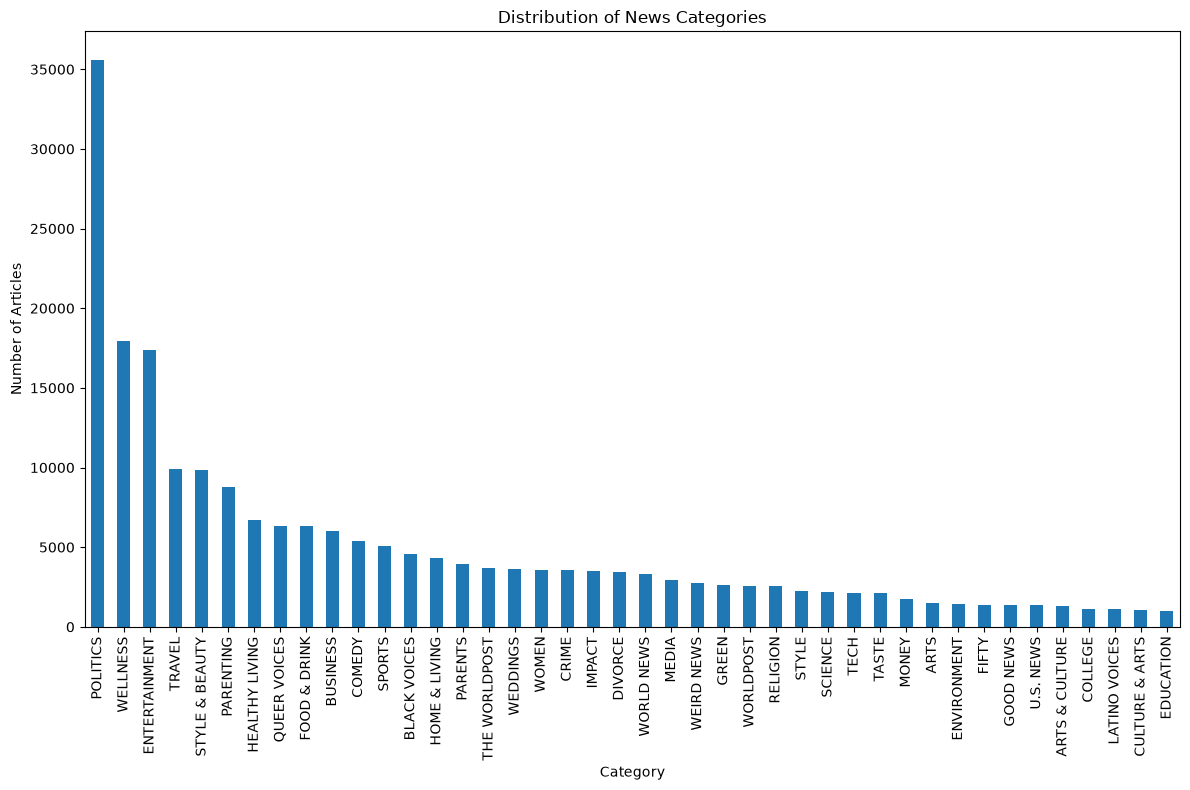

In [9]:
category_counts = df["category"].value_counts()
plt.figure(figsize=(12, 8))
category_counts.plot(kind="bar")
plt.title("Distribution of News Categories")
plt.xlabel("Category")
plt.ylabel("Number of Articles")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()



value_counts() is used to count the number of occurrences of each unique category in the target column. It helps us understand the class distribution and identify whether the dataset is balanced or imbalanced before training the machine learning model.

In [10]:
df.isnull()


,link,headline,category,short_description,authors,date
0,False,False,False,False,False,False
1,False,False,False,False,False,False
2,False,False,False,False,False,False
3,False,False,False,False,False,False
4,False,False,False,False,False,False
...,...,...,...,...,...,...
209522,False,False,False,False,False,False
209523,False,False,False,False,False,False
209524,False,False,False,False,False,False
209525,False,False,False,False,False,False


In [11]:
df.isnull().sum()

link                 0
headline             0
category             0
short_description    0
authors              0
date                 0
dtype: int64

checks the null values for each column

In [12]:
# Check actual NaN values
print("NaN values:")
print(df.isnull().sum())

# Check empty strings
print("\nEmpty strings:")
print((df == "").sum())

# Check spaces
print("\nWhitespace-only values:")
print((df.apply(lambda x: x.astype(str).str.strip() == "")).sum())

NaN values:
link                 0
headline             0
category             0
short_description    0
authors              0
date                 0
dtype: int64

Empty strings:
link                     0
headline                 6
category                 0
short_description    19712
authors              37418
date                     0
dtype: int64

Whitespace-only values:
link                     0
headline                 6
category                 0
short_description    19712
authors              37418
date                     0
dtype: int64


In [13]:
text_cols = ["headline", "short_description", "authors", "link"]

for col in text_cols:
    print(col, ":", df[col].isna().sum())
    print(col, "empty:", (df[col].fillna("").str.strip() == "").sum())

headline : 0
headline empty: 6
short_description : 0
short_description empty: 19712
authors : 0
authors empty: 37418
link : 0
link empty: 0


In [14]:
for col in text_cols:
    df[col] = df[col].fillna("").astype(str).str.strip()

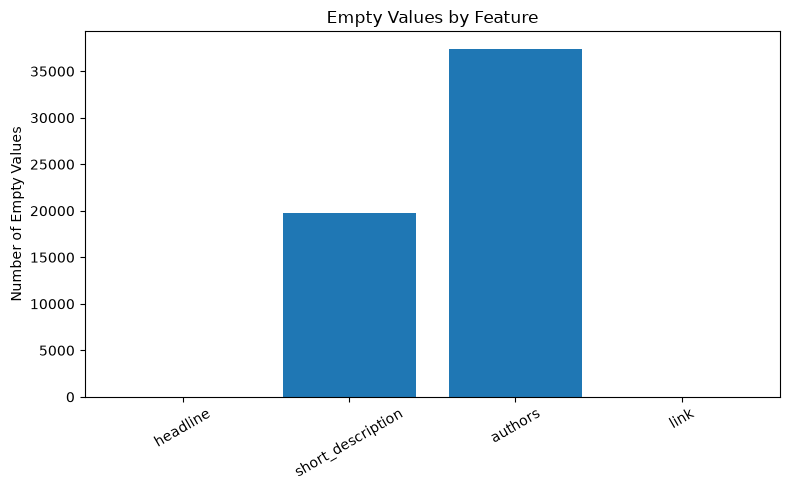

In [15]:


empty_counts = {
    col: df[col].eq("").sum()
    for col in text_cols
}

plt.figure(figsize=(8, 5))
plt.bar(empty_counts.keys(), empty_counts.values())
plt.title("Empty Values by Feature")
plt.ylabel("Number of Empty Values")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [16]:
df["headline"] = df["headline"].replace("", "unknown")
df["short_description"] = df["short_description"].replace(
    "", "no description")
df["authors"] = df["authors"].replace(
    "", "unknown")

In [17]:
text_cols = ["headline", "short_description", "authors", "link"]

for col in text_cols:
    print(col, ":", df[col].isna().sum())
    print(col, "empty:", (df[col].fillna("").str.strip() == "").sum())

headline : 0
headline empty: 0
short_description : 0
short_description empty: 0
authors : 0
authors empty: 0
link : 0
link empty: 0


In [18]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 13


Check whether any complete duplicate rows exist.

In [19]:
for col in df.columns:
    print(col, "duplicates:", df[col].duplicated().sum())

link duplicates: 41
headline duplicates: 1531
category duplicates: 209485
short_description duplicates: 22505
authors duplicates: 180360
date duplicates: 205637


In [20]:
duplicate_rows = df[df.duplicated(keep=False)]

print("Complete duplicate rows:", df.duplicated().sum())

Complete duplicate rows: 13


In [21]:
print("Before removing duplicates:", df.shape)

df = df.drop_duplicates()

print("After removing duplicates:", df.shape)

Before removing duplicates: (209527, 6)
After removing duplicates: (209514, 6)


In [22]:
print("Remaining duplicate rows:", df.duplicated().sum())

Remaining duplicate rows: 0


Duplicate Analysis: The dataset was checked for complete duplicate records, and 13 duplicate rows were identified. These exact duplicate records were removed during data cleaning to avoid redundant samples and ensure that the same record does not influence the model more than once.

In [23]:
df["headline_words"] = df["headline"].fillna("").str.split().str.len()
df["headline_chars"] = df["headline"].fillna("").str.len()

df["description_words"] = (
    df["short_description"].fillna("").str.split().str.len()
)

df["description_chars"] = (
    df["short_description"].fillna("").str.len()
)

df["author_count"] = (
    df["authors"].fillna("")
    .apply(lambda x: len([a for a in x.split(",") if a.strip()]))
)

df["link_length"] = df["link"].fillna("").str.len()

df["date"] = pd.to_datetime(df["date"])

df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["day"] = df["date"].dt.day
df["day_of_week"] = df["date"].dt.dayofweek

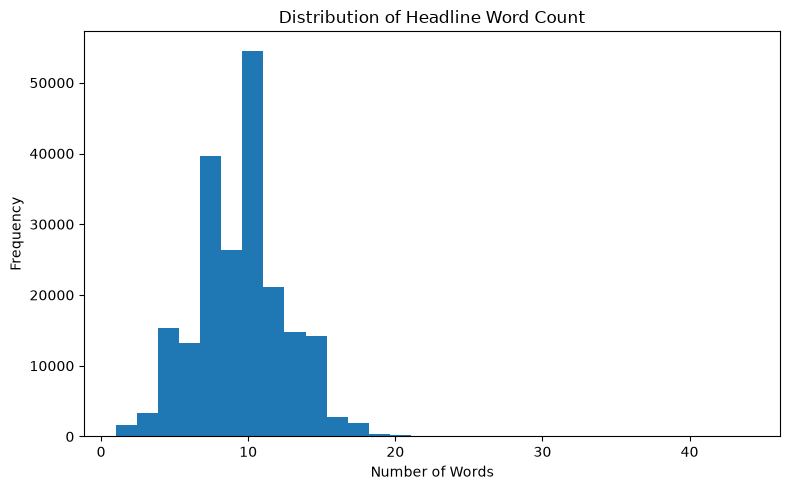

In [24]:
plt.figure(figsize=(8, 5))

plt.hist(df["headline_words"], bins=30)

plt.title("Distribution of Headline Word Count")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

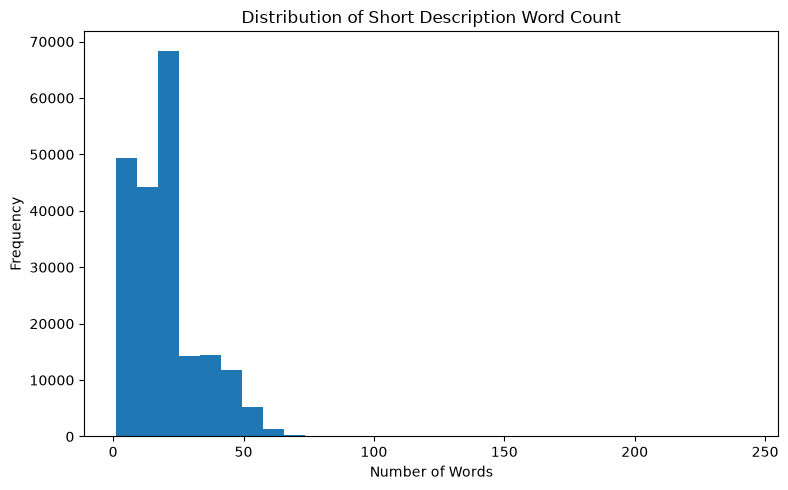

In [25]:


plt.figure(figsize=(8, 5))

plt.hist(df["description_words"], bins=30)

plt.title("Distribution of Short Description Word Count")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

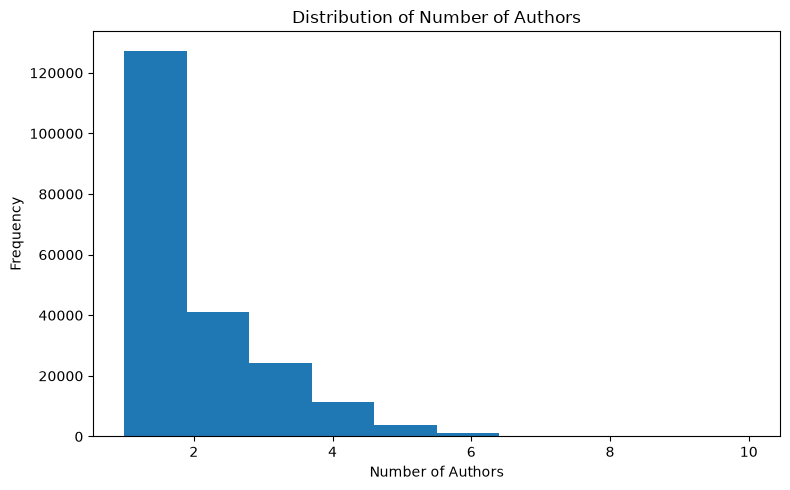

In [26]:
plt.figure(figsize=(8, 5))

plt.hist(df["author_count"], bins=10)

plt.title("Distribution of Number of Authors")
plt.xlabel("Number of Authors")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

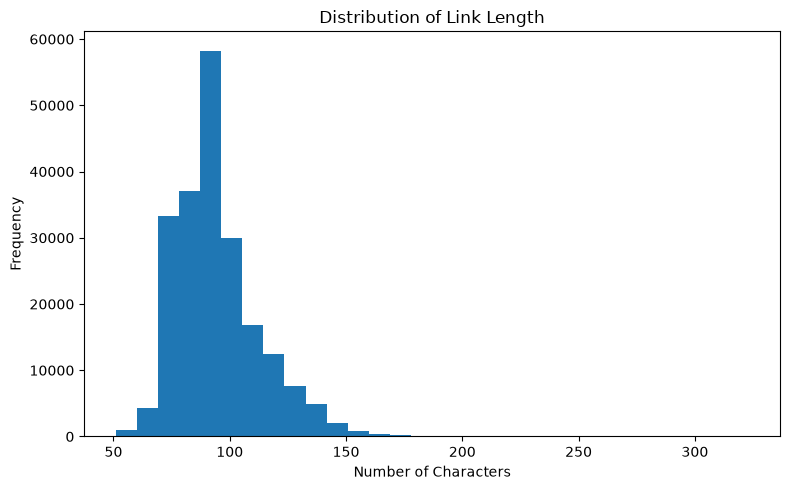

In [27]:
plt.figure(figsize=(8, 5))

plt.hist(df["link_length"], bins=30)

plt.title("Distribution of Link Length")
plt.xlabel("Number of Characters")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

code checks how many empty values exist

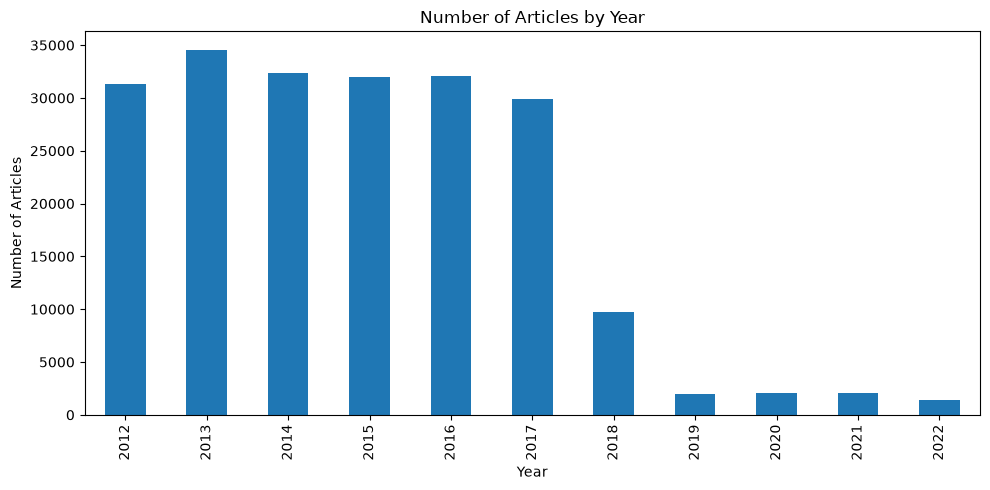

In [28]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")
plt.figure(figsize=(10, 5))
df["year"].value_counts().sort_index().plot(kind="bar")

plt.title("Number of Articles by Year")
plt.xlabel("Year")
plt.ylabel("Number of Articles")
plt.tight_layout()
plt.show()

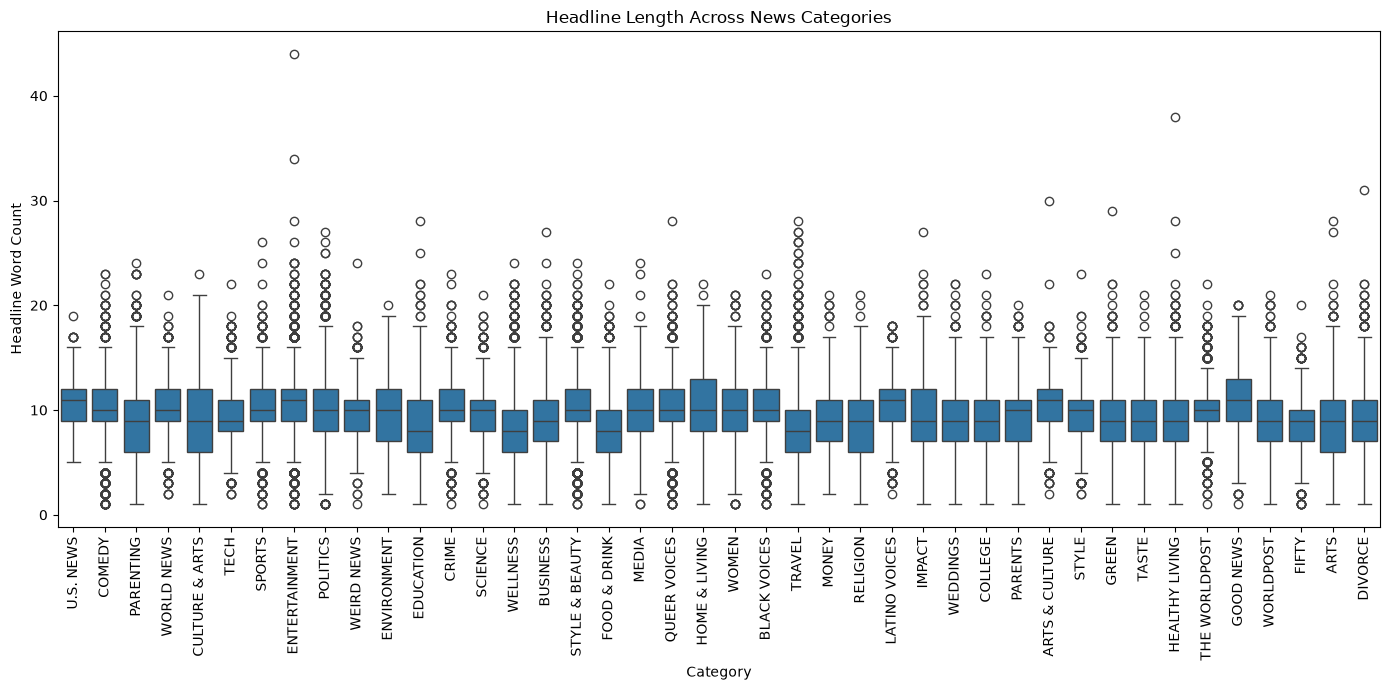

In [29]:
plt.figure(figsize=(14, 7))

sns.boxplot(
    data=df,
    x="category",
    y="headline_words"
)

plt.xticks(rotation=90)
plt.xlabel("Category")
plt.ylabel("Headline Word Count")
plt.title("Headline Length Across News Categories")
plt.tight_layout()
plt.show()

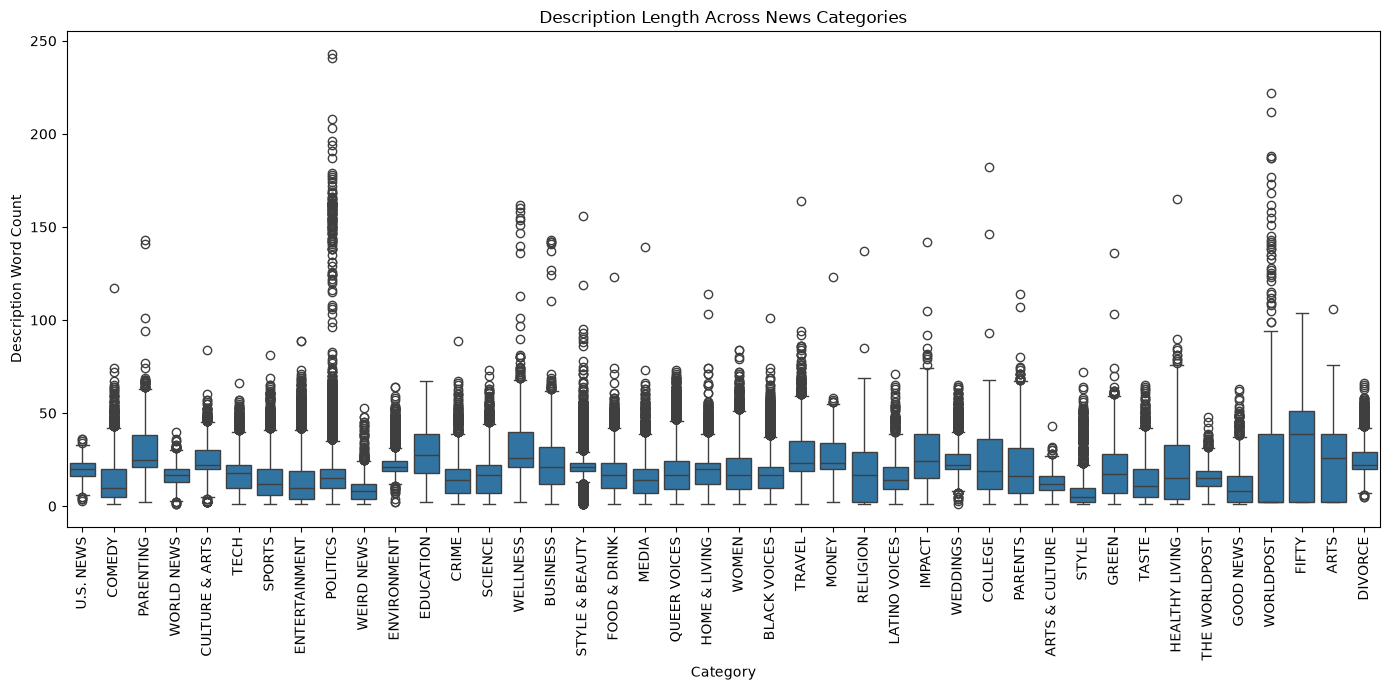

In [30]:
plt.figure(figsize=(14, 7))

sns.boxplot(
    data=df,
    x="category",
    y="description_words"
)

plt.xticks(rotation=90)
plt.xlabel("Category")
plt.ylabel("Description Word Count")
plt.title("Description Length Across News Categories")
plt.tight_layout()
plt.show()

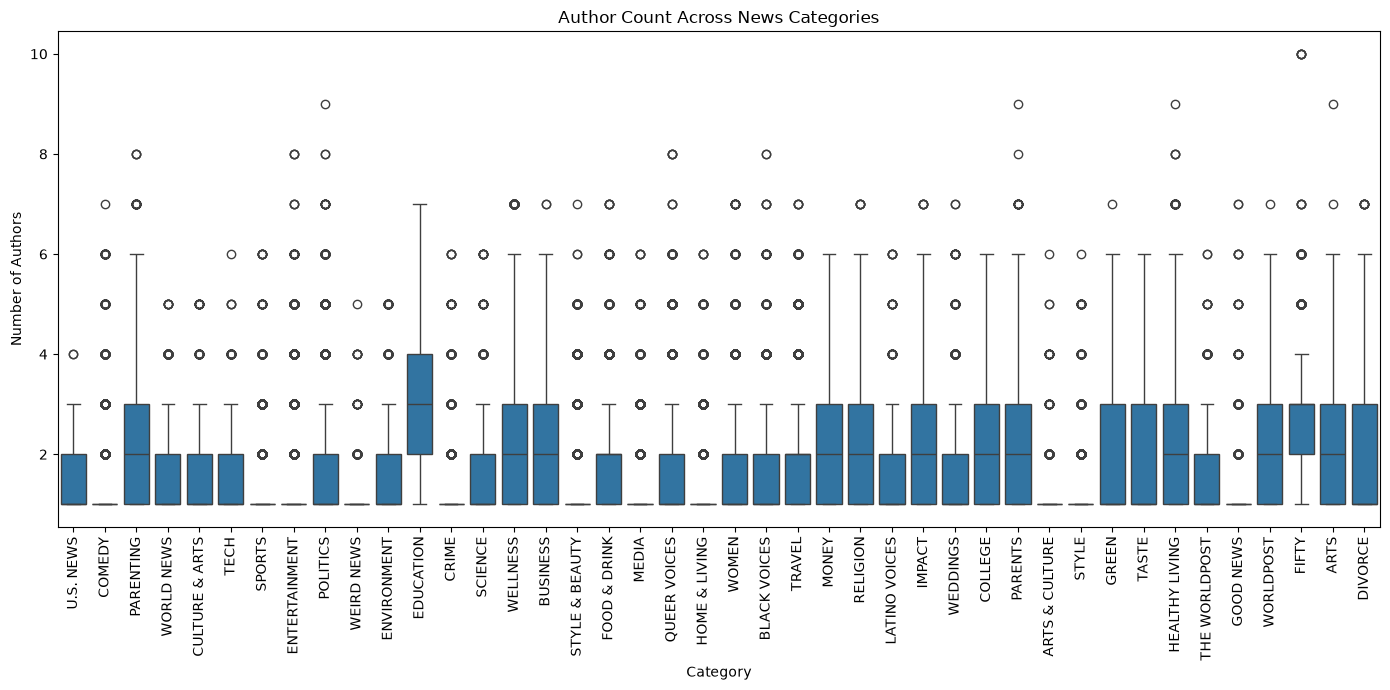

In [31]:
plt.figure(figsize=(14, 7))

sns.boxplot(
    data=df,
    x="category",
    y="author_count"
)

plt.xticks(rotation=90)
plt.xlabel("Category")
plt.ylabel("Number of Authors")
plt.title("Author Count Across News Categories")
plt.tight_layout()
plt.show()

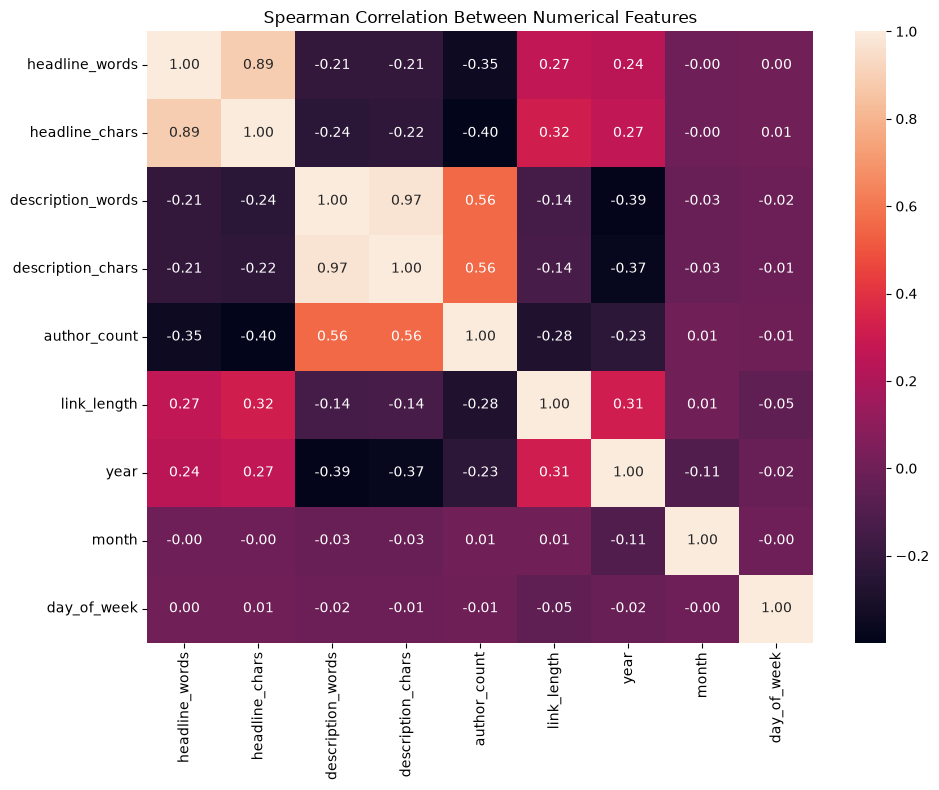

In [32]:
numeric_features = [
    "headline_words",
    "headline_chars",
    "description_words",
    "description_chars",
    "author_count",
    "link_length",
    "year",
    "month",
    "day_of_week"
]

corr = df[numeric_features].corr(method="spearman")

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f")

plt.title("Spearman Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

In [33]:
from sklearn.feature_selection import f_classif


numerical_features = [
    "headline_words",
    "description_words",
    "author_count",
    "year",
    "month",
    "day_of_week",
    "link_length"
]

X_numeric = df[numerical_features]
y = df["category"]

f_scores, p_values = f_classif(X_numeric, y)

feature_selection_results = pd.DataFrame({
    "Feature": numerical_features,
    "F_Score": f_scores,
    "P_Value": p_values
})

feature_selection_results = feature_selection_results.sort_values(
    by="F_Score",
    ascending=False
)

print(feature_selection_results)

             Feature      F_Score        P_Value
3               year  5844.951645   0.000000e+00
1  description_words  1160.617796   0.000000e+00
2       author_count   943.735239   0.000000e+00
6        link_length   544.285500   0.000000e+00
0     headline_words   451.059463   0.000000e+00
5        day_of_week   301.307937   0.000000e+00
4              month    23.158515  5.292180e-172


In [34]:
# Final selected numerical features based on
# correlation analysis and ANOVA F-test

selected_numerical_features = [
    "year",
    "description_words",
    "author_count",
    "link_length",
    "headline_words"
]

print("Selected Features:")
print(selected_numerical_features)

Selected Features:
['year', 'description_words', 'author_count', 'link_length', 'headline_words']


In [35]:
df["text"] = (
    df["headline"].fillna("") + " " +
    df["short_description"].fillna("")
)

In [36]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    return text
df['text'] = df['text'].apply(clean_text)


In [37]:
X = df["text"]
y = df["category"]
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

input feature X => text
output/Target feature y => category
Split the data into 80% training and 20% testing
test_size=20 => uses 20% data for testing 
random_state= 42 => It ensures you get the same split every time you run the code.
stratify=y => It ensures that the class/category proportions remain approximately the same in both training and testing datasets.

In [38]:
vectorizer= TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    stop_words="english",
    sublinear_tf=True
)



1.Actually the input feature is a text , to convert text to numerical we use TF-IDF technique .TfidfVectorizer() creates news text to numerical .
2.max_features=50000 => Keeps at most 50,000 words/terms as features.
3.ngram_range=(1,2) => Controls how many words are considered together.
      1 → unigrams (single words)
      2 → bigrams (two consecutive words)
4.remove english words that usually provide little information.

In [39]:
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

we use fit_transform() for training data  because fit learns the vocabulary and idf information ,we use only transform for the testing data because The test set must be processed using the same vocabulary and transformation learned from training data.

In [40]:
logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(X_train_tfidf, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

it creates a  empty LogisticRegression machine learning model with 1000 maximum no.of iterations (the model run 1000 times to find best solution). the model trains on X_train_tfidf(Input news text converted into numbers) and y_train(Correct news categories)

In [41]:
y_pred_lr = logistic_model.predict(X_test_tfidf)
print(y_pred_lr)

['QUEER VOICES' 'WELLNESS' 'POLITICS' ... 'ENTERTAINMENT' 'PARENTING'
 'ENTERTAINMENT']


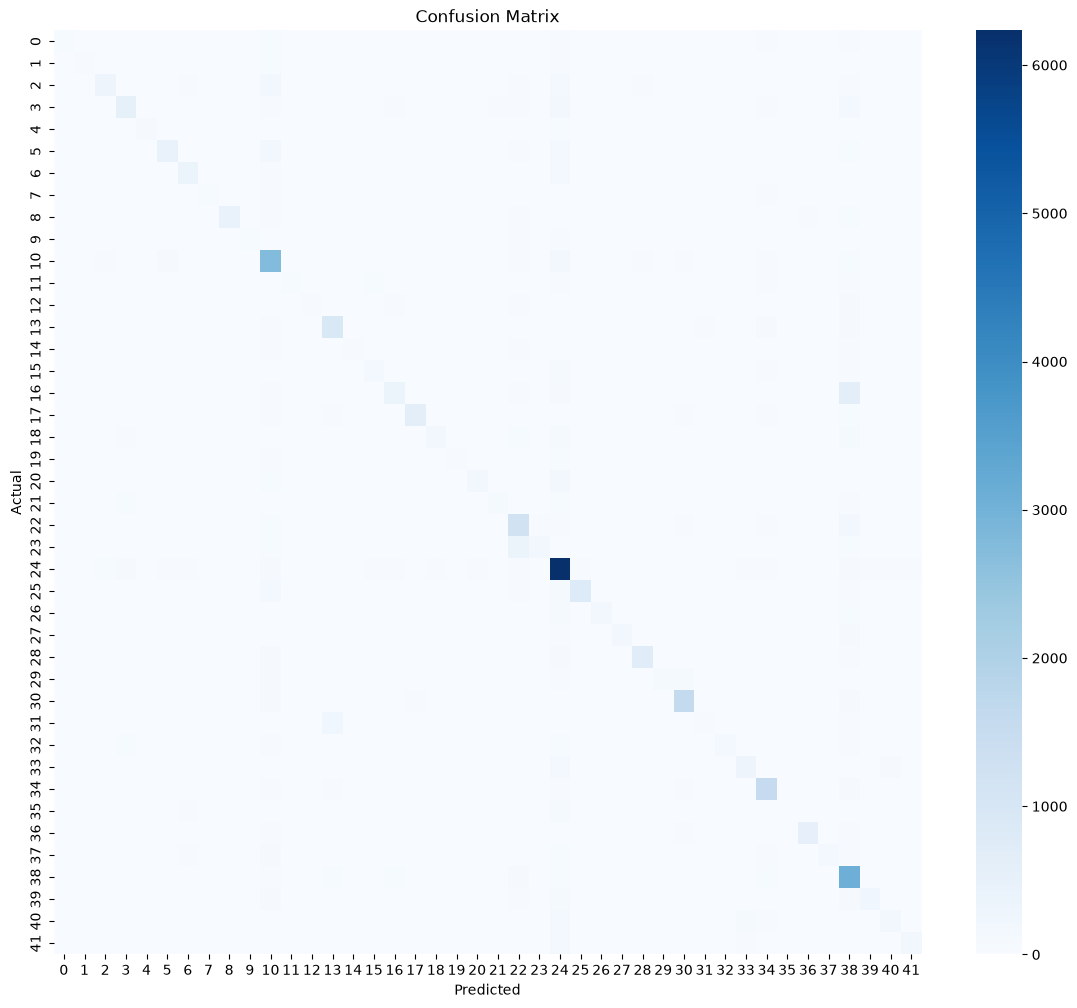

In [42]:
cm = confusion_matrix(y_test, y_pred_lr)
plt.figure(figsize=(14, 12))

sns.heatmap(cm, cmap="Blues")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [43]:
print(f"The Accuracy score for Logistic model is {accuracy_score(y_test, y_pred_lr)}")
print(f"The precision score for Logistic model is {precision_score(y_test, y_pred_lr,average="weighted")}")
print(f"The Recall score for Logistic model is {recall_score(y_test, y_pred_lr,average="weighted")}")
print(f"The f1 score for Logistic model is {f1_score(y_test, y_pred_lr,average="weighted")}")

SyntaxError: f-string: unmatched '(' (1460451248.py, line 2)

We add average='weighted' because our problem has multiple classes. It combines the precision/recall scores of all classes into one overall score, giving more importance to classes with more samples.

In [ ]:
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None


In [ ]:
y_pred_nb = nb_model.predict(X_test_tfidf)
print(y_pred_nb)

['POLITICS' 'WELLNESS' 'POLITICS' ... 'WELLNESS' 'WELLNESS'
 'ENTERTAINMENT']


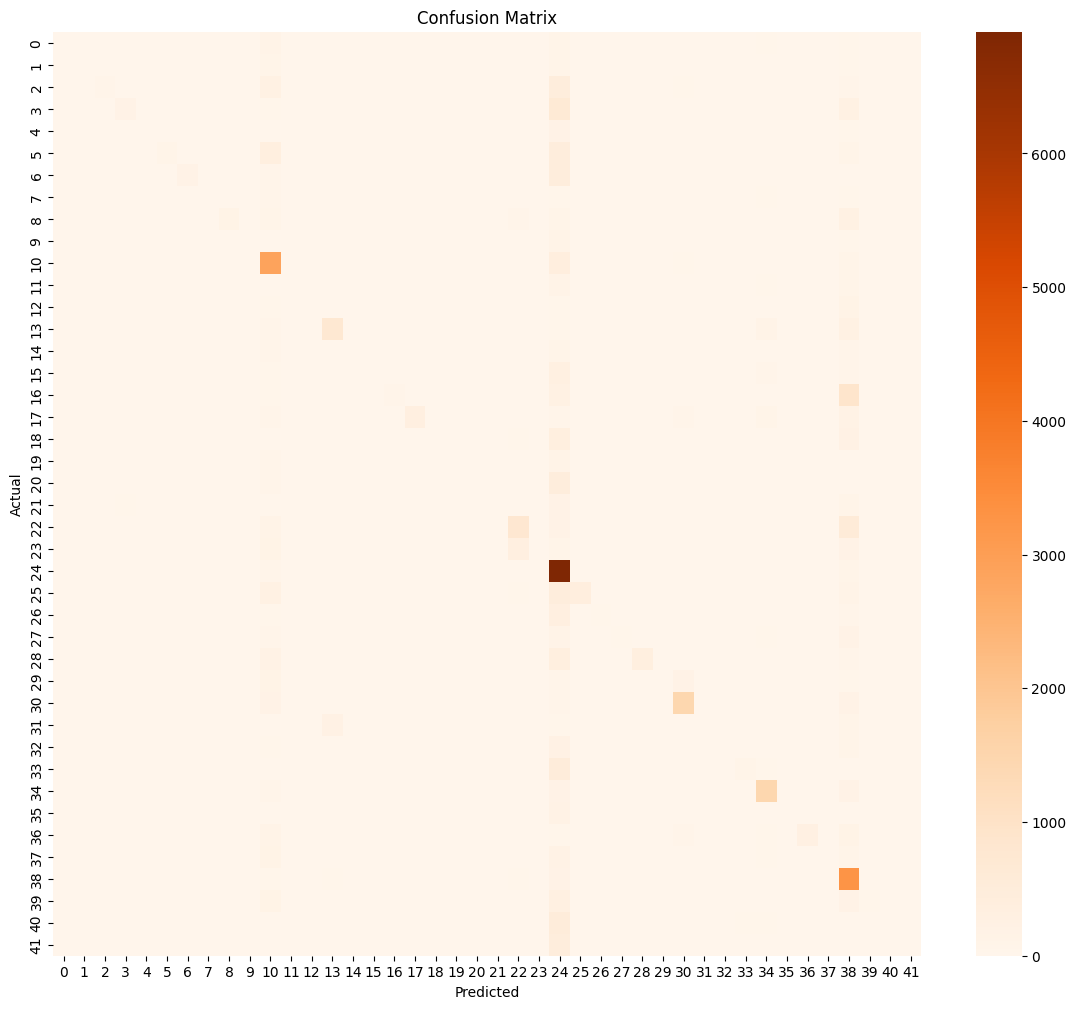

In [ ]:
cm = confusion_matrix(y_test, y_pred_nb)
plt.figure(figsize=(14, 12))

sns.heatmap(cm, cmap="Oranges")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [ ]:
print(f"The Accuracy score for Mutlinomial navie baues model is {accuracy_score(y_test, y_pred_nb)}")
print(f"The precision score for Mutlinomial navie bayes model is {precision_score(y_test, y_pred_nb,average="weighted")}")
print(f"The Recall score for Mutlinomial navie bayes model is {recall_score(y_test, y_pred_nb,average="weighted")}")
print(f"The f1 score for Mutlinomial navie bayes model is {f1_score(y_test, y_pred_nb,average="weighted")}")

The Accuracy score for Mutlinomial navie baues model is 0.478342839414839


C:\Users\LENOVO\AppData\Roaming\Python\Python314\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


The precision score for Mutlinomial navie bayes model is 0.5946765885914985
The Recall score for Mutlinomial navie bayes model is 0.478342839414839
The f1 score for Mutlinomial navie bayes model is 0.3889188606889077


In [ ]:
svm_model = LinearSVC(dual=False)
svm_model.fit(X_train_tfidf, y_train)

,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'squared_hinge'
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.For an intuitive visualization of the effects of scalingthe regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"multi_class multi_class: {'ovr', 'crammer_singer'}, default='ovr'Determines the multi-class strategy if `y` contains more thantwo classes.``""ovr""`` trains n_classes one-vs-rest classifiers, while``""crammer_singer""`` optimizes a joint objective over all classes.While `crammer_singer` is interesting from a theoretical perspectiveas it is consistent, it is seldom used in practice as it rarely leadsto better accuracy and is more expensive to compute.If ``""crammer_singer""`` is chosen, the options loss, penalty and dualwill be ignored.",'ovr'
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit an intercept. If set to True, the feature vectoris extended to include an intercept term: `[x_1, ..., x_n, 1]`, where1 corresponds to the intercept. If set to False, no intercept will beused in calculations (i.e. data is expected to be already centered).",True
,"intercept_scaling intercept_scaling: float, default=1.0When `fit_intercept` is True, the instance vector x becomes ``[x_1,..., x_n, intercept_scaling]``, i.e. a ""synthetic"" feature with aconstant value equal to `intercept_scaling` is appended to the instancevector. The intercept becomes intercept_scaling * synthetic featureweight. Note that liblinear internally penalizes the intercept,treating it like any other term in the feature vector. To reduce theimpact of the regularization on the intercept, the `intercept_scaling`parameter can be set to a value greater than 1; the higher the value of`intercept_scaling`, the lower the impact of regularization on it.Then, the weights become `[w_x_1, ..., w_x_n,w_intercept*intercept_scaling]`, where `w_x_1, ..., w_x_n` representthe feature weights and the intercept weight is scaled by`intercept_scaling`. This scaling allows the intercept term to have adifferent regularization behavior compared to the other features.",1
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to ``class_weight[i]*C`` forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: int, default=0Enable verbose output. Note that this setting takes advantage of aper-process runtime setting in liblinear that, if enabled, may not workproperly in a multithreaded context.",0
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo rando

In [ ]:
y_pred_svm = svm_model.predict(X_test_tfidf)
print(y_pred_svm)

['QUEER VOICES' 'WELLNESS' 'POLITICS' ... 'HEALTHY LIVING' 'PARENTING'
 'ENTERTAINMENT']


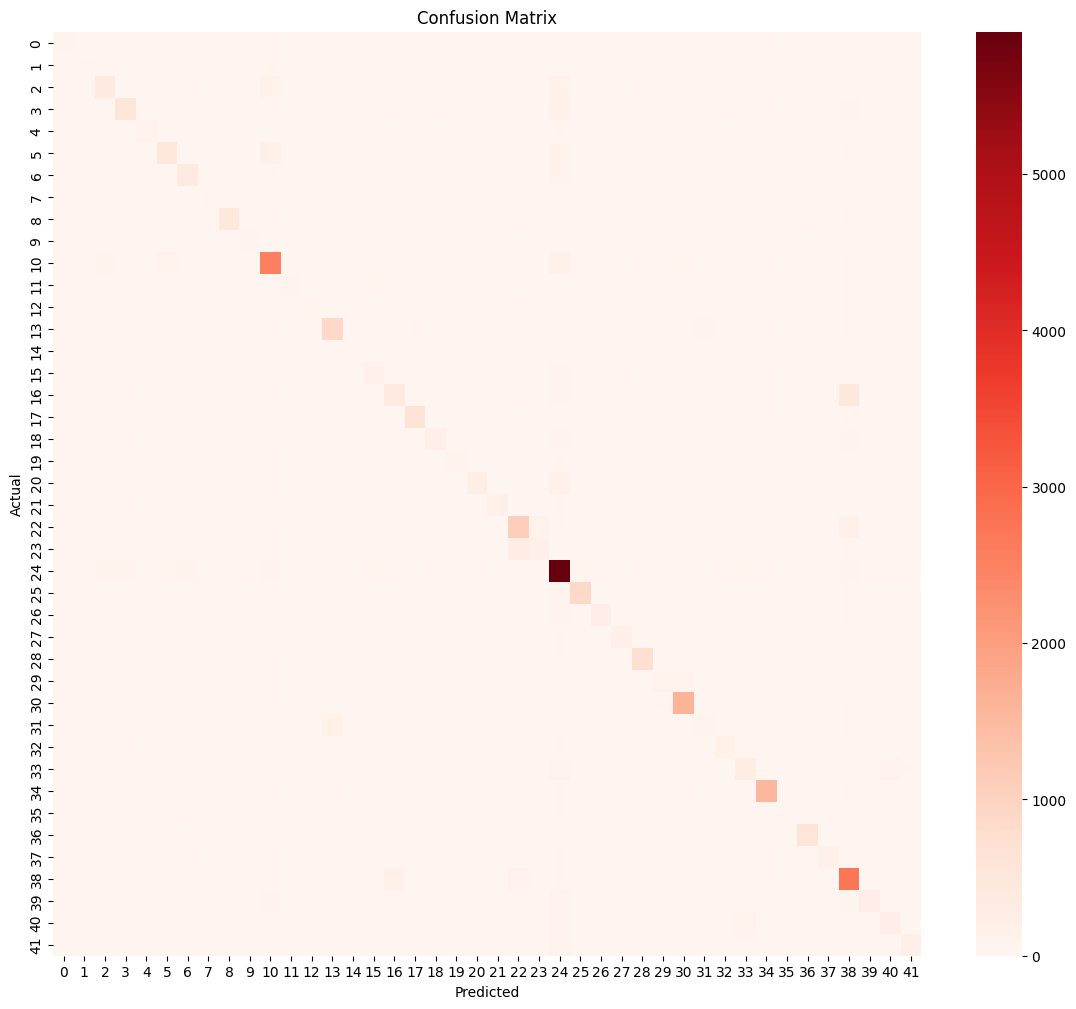

In [ ]:
cm = confusion_matrix(y_test, y_pred_svm)
plt.figure(figsize=(14, 12))

sns.heatmap(cm, cmap="Reds")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [ ]:
print("The classification metrics for SVM model are:")
print(f"Accuracy score :{accuracy_score(y_test, y_pred_svm)}")
print(f"The precision score : {precision_score(y_test, y_pred_svm,average="weighted")}")
print(f"The Recall score : {recall_score(y_test, y_pred_svm,average="weighted")}")
print(f"The f1 score :{ f1_score(y_test, y_pred_svm,average="weighted")}")

The classification metrics for SVM model are:
Accuracy score :0.6134644297544328
The precision score : 0.5968491887610197
The Recall score : 0.6134644297544328
The f1 score :0.5997062589200239


In [ ]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Multinomial Naive Bayes",
        "Linear SVM"
    ],
    
    "Accuracy": [
        (accuracy_score(y_test, y_pred_lr)*100),
        (accuracy_score(y_test, y_pred_nb)*100),
        (accuracy_score(y_test, y_pred_svm)*100)
    ],
    })

results

,Model,Accuracy
0,Logistic Regression,61.048135
1,Multinomial Naive Bayes,47.834284
2,Linear SVM,61.346443


checks the accuarcies of models

In [ ]:


from sklearn.feature_extraction.text import CountVectorizer



count_vectorizer = CountVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    stop_words="english"
)

X_train_count = count_vectorizer.fit_transform(X_train)
X_test_count = count_vectorizer.transform(X_test)

print("Training shape:", X_train_count.shape)
print("Testing shape:", X_test_count.shape)



models = {
    
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),
    
    "Multinomial Naive Bayes": MultinomialNB(),
    
    "Linear SVM": LinearSVC(
        random_state=42
    )
}

count_results = []

for name, model in models.items():
    
    print(f"\nTraining {name}...")
    
    # Train model
    model.fit(X_train_count, y_train)
    
    # Predictions
    y_pred = model.predict(X_test_count)
    
    # Evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    
    macro_f1 = f1_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )
    
    weighted_f1 = f1_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )
    
    
    count_results.append({
        "Feature Extraction": "CountVectorizer",
        "Model": name,
        "Accuracy": accuracy,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1
    })
    
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Macro F1: {macro_f1:.4f}")
    print(f"Weighted F1: {weighted_f1:.4f}")



count_results_df = pd.DataFrame(count_results)

count_results_df = count_results_df.sort_values(
    by=["Weighted F1", "Accuracy"],
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 70)
print("COUNT VECTORIZER MODEL COMPARISON")
print("=" * 70)

print(count_results_df)

Training shape: (167611, 50000)
Testing shape: (41903, 50000)

Training Logistic Regression...
Accuracy: 0.6035
Macro F1: 0.4881
Weighted F1: 0.5940

Training Multinomial Naive Bayes...
Accuracy: 0.5959
Macro F1: 0.4244
Weighted F1: 0.5678

Training Linear SVM...
Accuracy: 0.5470
Macro F1: 0.4310
Weighted F1: 0.5436

COUNT VECTORIZER MODEL COMPARISON
  Feature Extraction                    Model  Accuracy  Macro F1  Weighted F1
0    CountVectorizer      Logistic Regression  0.603537  0.488121     0.593950
1    CountVectorizer  Multinomial Naive Bayes  0.595924  0.424431     0.567838
2    CountVectorizer               Linear SVM  0.547025  0.430970     0.543650


In [ ]:


tfidf_results = results.copy()

tfidf_results["Feature Extraction"] = "TF-IDF"


count_comparison = count_results_df.copy()

# Convert decimal accuracy to percentage
count_comparison["Accuracy"] = (
    count_comparison["Accuracy"] * 100
)


tfidf_comparison = tfidf_results[
    ["Feature Extraction", "Model", "Accuracy"]
]

count_comparison = count_comparison[
    ["Feature Extraction", "Model", "Accuracy"]
]


final_comparison = pd.concat(
    [tfidf_comparison, count_comparison],
    ignore_index=True
)

final_comparison = final_comparison.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)




print("=" * 70)
print("TF-IDF vs COUNT VECTORIZER COMPARISON")
print("=" * 70)

print(final_comparison)

TF-IDF vs COUNT VECTORIZER COMPARISON
  Feature Extraction                    Model   Accuracy
0             TF-IDF               Linear SVM  61.346443
1             TF-IDF      Logistic Regression  61.048135
2    CountVectorizer      Logistic Regression  60.353674
3    CountVectorizer  Multinomial Naive Bayes  59.592392
4    CountVectorizer               Linear SVM  54.702527
5             TF-IDF  Multinomial Naive Bayes  47.834284


In [ ]:


# Different C values to test
C_values = [0.01, 0.05, 0.1, 0.5, 1, 2, 5, 10]

svm_tuning_results = []

for C in C_values:

    print(f"\nTesting Linear SVM with C = {C}")

    model = LinearSVC(
        C=C,
        random_state=42,
        max_iter=5000
    )

    # Train
    model.fit(X_train_tfidf, y_train)

    # Predict
    y_pred = model.predict(X_test_tfidf)

    # Metrics
    accuracy = accuracy_score(y_test, y_pred) * 100

    macro_f1 = f1_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    ) * 100

    weighted_f1 = f1_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    ) * 100

    svm_tuning_results.append({
        "C": C,
        "Accuracy": accuracy,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1
    })


# Create results table
svm_tuning_df = pd.DataFrame(svm_tuning_results)

# Sort by Weighted F1
svm_tuning_df = svm_tuning_df.sort_values(
    by=["Weighted F1", "Accuracy"],
    ascending=False
).reset_index(drop=True)

print("\n===== LINEAR SVM TUNING RESULTS =====")

print(svm_tuning_df)


Testing Linear SVM with C = 0.01

Testing Linear SVM with C = 0.05

Testing Linear SVM with C = 0.1

Testing Linear SVM with C = 0.5

Testing Linear SVM with C = 1

Testing Linear SVM with C = 2

Testing Linear SVM with C = 5

Testing Linear SVM with C = 10

===== LINEAR SVM TUNING RESULTS =====
       C   Accuracy   Macro F1  Weighted F1
0   0.50  62.647066  49.530245    60.883526
1   1.00  61.346443  48.591700    59.970626
2   0.10  62.133976  46.847333    59.167568
3   2.00  59.449204  47.146693    58.443341
4   0.05  60.532659  43.547700    56.821278
5   5.00  56.888528  44.904190    56.270221
6  10.00  55.072429  43.243406    54.641616
7   0.01  54.258645  32.640804    48.202505


In [ ]:
final_svm = LinearSVC(
    C=0.5,
    random_state=42,
    max_iter=5000
)

# Train
final_svm.fit(X_train_tfidf, y_train)

# Predict
y_pred_final = final_svm.predict(X_test_tfidf)



final_accuracy = accuracy_score(y_test, y_pred_final) * 100

print("FINAL LINEAR SVM ACCURACY:", round(final_accuracy, 2), "%")



print("\nCLASSIFICATION REPORT:\n")

print(
    classification_report(
        y_test,
        y_pred_final,
        zero_division=0
    )
)

FINAL LINEAR SVM ACCURACY: 62.65 %

CLASSIFICATION REPORT:

                precision    recall  f1-score   support

          ARTS       0.38      0.25      0.30       302
ARTS & CULTURE       0.39      0.19      0.25       268
  BLACK VOICES       0.54      0.44      0.48       917
      BUSINESS       0.51      0.48      0.50      1198
       COLLEGE       0.50      0.46      0.48       229
        COMEDY       0.58      0.44      0.50      1080
         CRIME       0.54      0.58      0.56       712
CULTURE & ARTS       0.60      0.28      0.38       215
       DIVORCE       0.81      0.73      0.76       685
     EDUCATION       0.48      0.36      0.41       203
 ENTERTAINMENT       0.64      0.76      0.69      3473
   ENVIRONMENT       0.51      0.26      0.34       289
         FIFTY       0.47      0.20      0.28       280
  FOOD & DRINK       0.64      0.73      0.68      1268
     GOOD NEWS       0.37      0.20      0.26       280
         GREEN       0.41      0.36      0.

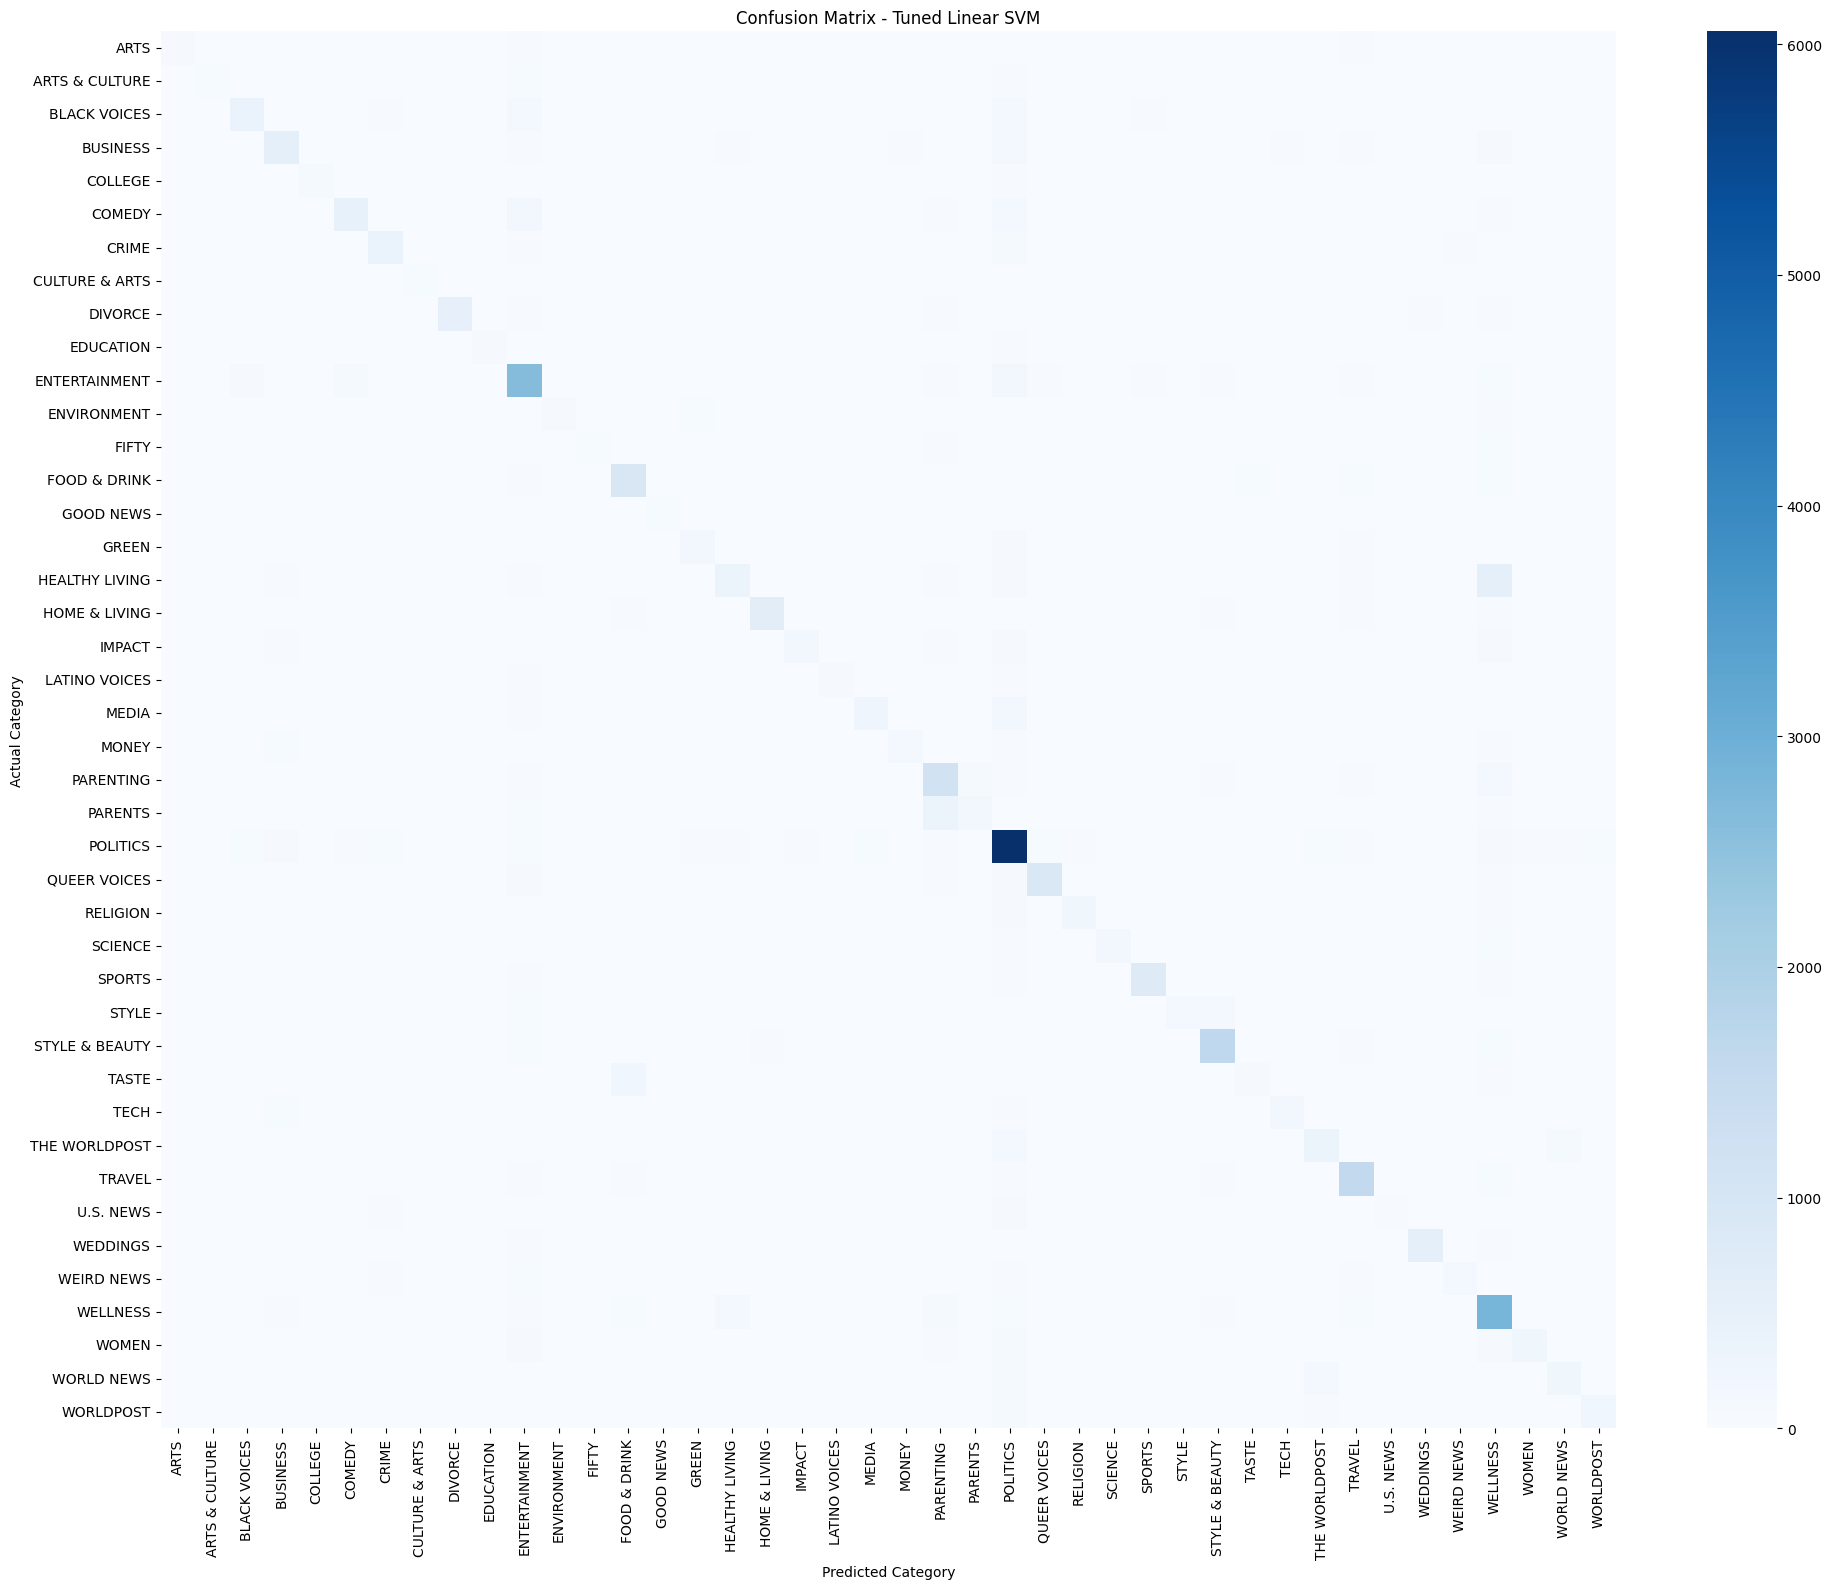

In [ ]:
# Get all category labels
labels = sorted(y_test.unique())

# Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred_final,
    labels=labels
)

# Plot
plt.figure(figsize=(20, 16))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Confusion Matrix - Tuned Linear SVM")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

plt.tight_layout()
plt.show()

In [ ]:
# Test the final model

y_pred_final = final_svm.predict(X_test_tfidf)

print("Testing completed successfully!")

Testing completed successfully!


In [ ]:
# New news text
new_news = [
    "The government announces new policies to improve the country's economy"
]

# Convert text using the SAME fitted TF-IDF vectorizer
new_news_tfidf = vectorizer.transform(new_news)

# Predict category
prediction = final_svm.predict(new_news_tfidf)

print("Predicted Category:", prediction[0])

Predicted Category: POLITICS


A new unseen news statement was given to the trained Linear SVM model. The model predicted its category as POLITICS.

In [ ]:
new_news = [
    "The team won the championship after an exciting final match",
    "Scientists discover a new method for treating diseases",
    "A new movie is released and receives positive reviews",
   "Researchers are developing new methods to reduce plastic waste and protect the environment.",
   "Local volunteers come together to help families affected by a recent community crisis.",
    "A new exhibition explores traditional art and cultural history through paintings and sculptures."]
new_news_tfidf = vectorizer.transform(new_news)

predictions = final_svm.predict(new_news_tfidf)

for news, prediction in zip(new_news, predictions):
    print("News:", news)
    print("Predicted Category:", prediction)
    print()

News: The team won the championship after an exciting final match
Predicted Category: SPORTS

News: Scientists discover a new method for treating diseases
Predicted Category: SCIENCE

News: A new movie is released and receives positive reviews
Predicted Category: ENTERTAINMENT

News: Researchers are developing new methods to reduce plastic waste and protect the environment.
Predicted Category: GREEN

News: Local volunteers come together to help families affected by a recent community crisis.
Predicted Category: IMPACT

News: A new exhibition explores traditional art and cultural history through paintings and sculptures.
Predicted Category: CULTURE & ARTS



Conclusion:
In this project, a News Category dataset was analyzed and used to build a multi-class classification model. The text data was converted into numerical features using TF-IDF. Multiple machine learning models were trained and compared, including Logistic Regression, Multinomial Naive Bayes, and Linear SVM. Linear SVM performed better than the other models. Hyperparameter tuning and TF-IDF tuning were performed to improve the model. The final Linear SVM achieved an accuracy of 62.42% on the test data. Class balancing was also tested, but it did not improve the overall performance, so it was not used in the final model. The final model was also tested with new unseen news text and successfully predicted their categories.

In [ ]:
# ============================================================
# MLOPS EVALUATION CONFIGURATION + DATA VALIDATION
# ============================================================

RANDOM_STATE = 42
TEST_SIZE = 0.15
SVM_C = 0.5

# Required columns for this controlled experiment
required_columns = [
    "headline", "short_description", "authors", "date", "category"
]
missing_columns = [c for c in required_columns if c not in df.columns]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

print("Data validation: PASSED")
print("Rows:", len(df))
print("Original classes:", df["category"].nunique())

# Re-create the cleaned text so this section is independent of later notebook edits.
df["text_eval"] = (
    df["headline"].fillna("").astype(str) + " " +
    df["short_description"].fillna("").astype(str)
).str.lower().str.replace(r"[^a-z\s]", "", regex=True).str.replace(r"\s+", " ", regex=True).str.strip()

# Ensure year is available for the metadata experiment.
df["year_eval"] = pd.to_datetime(df["date"], errors="coerce").dt.year.fillna(0).astype(int)

df["authors_eval"] = df["authors"].fillna("unknown").astype(str).str.strip()
df.loc[df["authors_eval"] == "", "authors_eval"] = "unknown"

print("Text preparation: PASSED")
print("Missing text rows:", int(df["text_eval"].eq("").sum()))


In [ ]:
# ============================================================
# TARGET ENGINEERING: 42 ORIGINAL LABELS -> 33 MERGED LABELS
# ============================================================

merge_map = {
    # Arts-related labels
    "ARTS": "ARTS & CULTURE",
    "ARTS & CULTURE": "ARTS & CULTURE",
    "CULTURE & ARTS": "ARTS & CULTURE",

    # Parenting-related labels
    "PARENTING": "PARENTING",
    "PARENTS": "PARENTING",

    # Style-related labels
    "STYLE": "STYLE & BEAUTY",
    "STYLE & BEAUTY": "STYLE & BEAUTY",

    # WorldPost duplicate labels
    "THE WORLDPOST": "WORLDPOST",
    "WORLDPOST": "WORLDPOST",

    # Environment-related labels
    "GREEN": "ENVIRONMENT & GREEN",
    "ENVIRONMENT": "ENVIRONMENT & GREEN",

    # Health-related labels
    "HEALTHY LIVING": "WELLNESS",
    "WELLNESS": "WELLNESS",

    # Food-related labels
    "FOOD & DRINK": "FOOD & DRINK",
    "TASTE": "FOOD & DRINK",

    # Education-related labels
    "COLLEGE": "EDUCATION",
    "EDUCATION": "EDUCATION",

    # Relationship/life-event labels
    "WEDDINGS": "RELATIONSHIPS",
    "DIVORCE": "RELATIONSHIPS"
}

# Keep all labels that are not explicitly merged unchanged.
df["merged_category"] = df["category"].map(merge_map).fillna(df["category"])

original_classes = df["category"].nunique()
merged_classes = df["merged_category"].nunique()

print("Original classes:", original_classes)
print("Merged classes:", merged_classes)

if merged_classes != 33:
    raise ValueError(
        f"Expected 33 merged classes, but got {merged_classes}. "
        "Check merge_map before running the experiments."
    )

print("Target engineering: PASSED — 42 -> 33 classes")


In [ ]:
# ============================================================
# FIXED 15% HOLDOUT — SAME INDICES FOR EVERY VARIANT
# ============================================================

indices = np.arange(len(df))

train_idx, test_idx = train_test_split(
    indices,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=df["merged_category"]
)

print("Train rows:", len(train_idx))
print("Test rows:", len(test_idx))
print("Test percentage:", round(len(test_idx) / len(df) * 100, 2), "%")

# Same article indices are reused for every experiment.


In [ ]:
# ============================================================
# REPRODUCIBLE EXPERIMENT FUNCTION
# ============================================================

def run_svm_experiment(name, feature_mode):
    """Run one controlled TF-IDF + Linear SVM experiment."""

    if feature_mode == "text":
        feature_text = df["text_eval"]
    elif feature_mode == "text_metadata":
        # Authors and year are appended as tokens so they can be handled by TF-IDF
        # without changing the existing Linear SVM model.
        feature_text = (
            df["text_eval"] + " author_" +
            df["authors_eval"].str.lower().str.replace(r"[^a-z\s]", "", regex=True).str.replace(r"\s+", "_", regex=True) +
            " year_" + df["year_eval"].astype(str)
        )
    else:
        raise ValueError("feature_mode must be 'text' or 'text_metadata'")

    X_train = feature_text.iloc[train_idx]
    X_test = feature_text.iloc[test_idx]
    y_train = df["merged_category"].iloc[train_idx]
    y_test = df["merged_category"].iloc[test_idx]

    vectorizer = TfidfVectorizer(
        max_features=50000,
        ngram_range=(1, 2),
        stop_words="english",
        sublinear_tf=True
    )

    X_train_tfidf = vectorizer.fit_transform(X_train)
    X_test_tfidf = vectorizer.transform(X_test)

    model = LinearSVC(
        C=SVM_C,
        random_state=RANDOM_STATE,
        max_iter=5000
    )

    model.fit(X_train_tfidf, y_train)
    predictions = model.predict(X_test_tfidf)

    accuracy = accuracy_score(y_test, predictions) * 100
    macro_f1 = f1_score(
        y_test, predictions, average="macro", zero_division=0
    )

    return {
        "Variant": name,
        "Classes": y_train.nunique(),
        "Accuracy": accuracy,
        "Macro-F1": macro_f1,
        "Train rows": len(train_idx),
        "Test rows": len(test_idx)
    }
